# Credit Card Fraud Detection - Data Preparation

In [76]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Set display options for better readability
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

## 1. Data Understanding

In [77]:
# Load the dataset
data_path = "dataset/card_transdata.csv"
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully!
Dataset shape: (1000000, 8)
Number of rows: 1,000,000
Number of columns: 8


In [78]:
# Display basic information about the dataset
print("1. Column Names and Data Types:")
print(df.dtypes)
print("\n2. Dataset Info:")
df.info()
print("\n3. First 5 rows:")
print(df.head())

1. Column Names and Data Types:
distance_from_home                float64
distance_from_last_transaction    float64
ratio_to_median_purchase_price    float64
repeat_retailer                   float64
used_chip                         float64
used_pin_number                   float64
online_order                      float64
fraud                             float64
dtype: object

2. Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 8 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   distance_from_home              1000000 non-null  float64
 1   distance_from_last_transaction  1000000 non-null  float64
 2   ratio_to_median_purchase_price  1000000 non-null  float64
 3   repeat_retailer                 1000000 non-null  float64
 4   used_chip                       1000000 non-null  float64
 5   used_pin_number                 1000000 non


Target column identified: 'fraud'

Class distribution:
fraud
0.0    912597
1.0     87403
Name: count, dtype: int64

Class distribution (percentages):
fraud
0.0    91.2597
1.0     8.7403
Name: proportion, dtype: float64


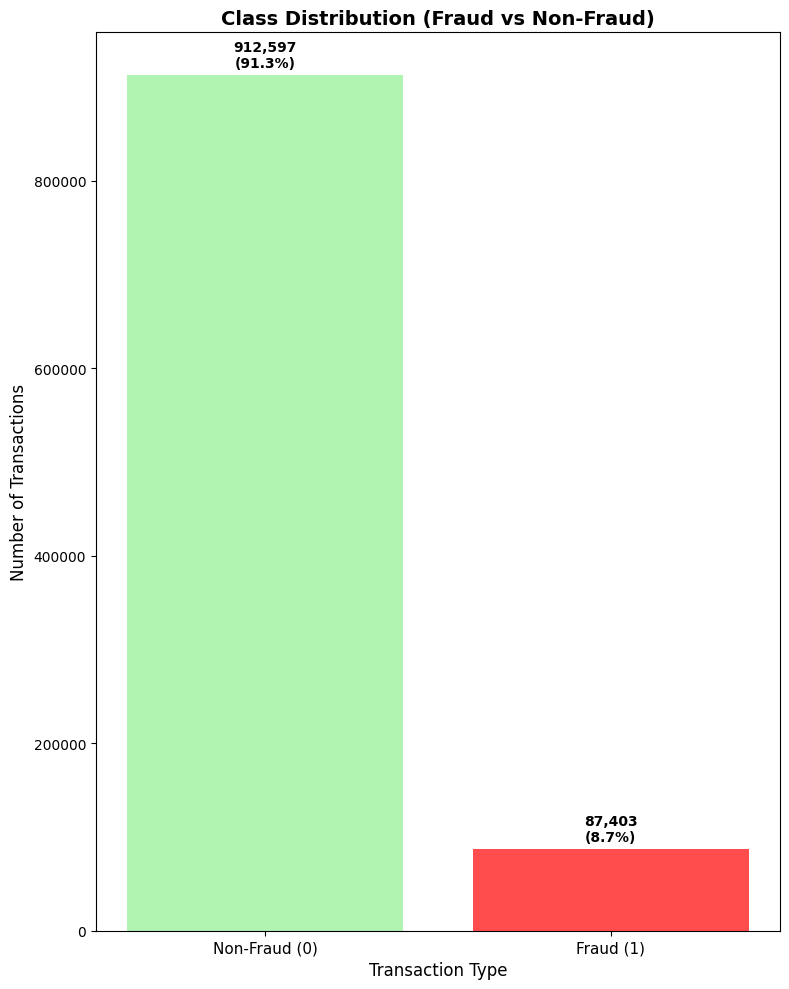

In [79]:
# Identify potential target columns (common names for fraud detection)
potential_targets = ['fraud', 'is_fraud', 'target', 'class', 'label', 'fraudulent']
target_col = None

for col in df.columns:
    if col.lower() in potential_targets:
        target_col = col
        break

if target_col:
    print(f"\nTarget column identified: '{target_col}'")
    print(f"\nClass distribution:")
    print(df[target_col].value_counts())
    print(f"\nClass distribution (percentages):")
    print(df[target_col].value_counts(normalize=True) * 100)
    
    # Visualize class distribution
    plt.figure(figsize=(8, 10))
    counts = df[target_col].value_counts().sort_index()
    bars = plt.bar(range(len(counts)), counts, color=['lightgreen', 'red'], alpha=0.7)
    plt.title('Class Distribution (Fraud vs Non-Fraud)', fontsize=14, fontweight='bold')
    plt.xlabel('Transaction Type', fontsize=12)
    plt.ylabel('Number of Transactions', fontsize=12)
    plt.xticks(range(len(counts)), ['Non-Fraud (0)', 'Fraud (1)'], fontsize=11)
    
    # Add value labels on bars
    for i, (bar, count) in enumerate(zip(bars, counts)):
        plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 5000,
                f'{count:,}\n({count/len(df)*100:.1f}%)', 
                ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
else:
    print("\nTarget column not automatically identified. Please examine the columns:")
    print(df.columns.tolist())
    print("\nPlease specify the target column manually in the next cell.")

In [80]:
print("\n1. Missing Values:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])
if missing_values.sum() == 0:
    print("No missing values found")

print("\n2. Duplicate Rows:")
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

print("\n3. Data Types Summary:")
print(f"Numerical columns: {df.select_dtypes(include=[np.number]).columns.tolist()}")
print(f"Categorical columns: {df.select_dtypes(include=['object']).columns.tolist()}")

print("\n4. Basic Statistical Summary:")
print(df.describe())


1. Missing Values:
Series([], dtype: int64)
No missing values found

2. Duplicate Rows:
Number of duplicate rows: 0

3. Data Types Summary:
Numerical columns: ['distance_from_home', 'distance_from_last_transaction', 'ratio_to_median_purchase_price', 'repeat_retailer', 'used_chip', 'used_pin_number', 'online_order', 'fraud']
Categorical columns: []

4. Basic Statistical Summary:
       distance_from_home  distance_from_last_transaction  ratio_to_median_purchase_price  repeat_retailer       used_chip  used_pin_number    online_order           fraud
count      1000000.000000                  1000000.000000                  1000000.000000   1000000.000000  1000000.000000   1000000.000000  1000000.000000  1000000.000000
mean            26.628792                        5.036519                        1.824182         0.881536        0.350399         0.100608        0.650552        0.087403
std             65.390784                       25.843093                        2.799589         0.32

## 2. Data Cleaning

Now we'll perform basic data cleaning operations including handling missing values and removing duplicates.

In [81]:
# Create a copy of the original dataset for cleaning
df_clean = df.copy()
print(f"Original dataset shape: {df.shape}")

# 1. Handle Missing Values
missing_before = df_clean.isnull().sum().sum()
print(f"Total missing values before cleaning: {missing_before}")

if missing_before > 0:
    # For numerical columns: fill with median
    numerical_cols = df_clean.select_dtypes(include=[np.number]).columns
    for col in numerical_cols:
        if df_clean[col].isnull().sum() > 0:
            median_value = df_clean[col].median()
            df_clean[col].fillna(median_value, inplace=True)
            print(f"Filled {col} missing values with median: {median_value}")
    
    # For categorical columns: fill with mode
    categorical_cols = df_clean.select_dtypes(include=['object']).columns
    for col in categorical_cols:
        if df_clean[col].isnull().sum() > 0:
            mode_value = df_clean[col].mode()[0]
            df_clean[col].fillna(mode_value, inplace=True)
            print(f"Filled {col} missing values with mode: {mode_value}")

missing_after = df_clean.isnull().sum().sum()
print(f"Total missing values after cleaning: {missing_after}")

# 2. Remove Duplicate Rows
duplicates_before = df_clean.duplicated().sum()
print(f"Duplicate rows before removal: {duplicates_before}")

df_clean = df_clean.drop_duplicates()
duplicates_after = df_clean.duplicated().sum()
print(f"Duplicate rows after removal: {duplicates_after}")

print(f"\nFinal cleaned dataset shape: {df_clean.shape}")
print(f"Rows removed: {df.shape[0] - df_clean.shape[0]}")

Original dataset shape: (1000000, 8)
Total missing values before cleaning: 0
Total missing values after cleaning: 0
Duplicate rows before removal: 0
Duplicate rows after removal: 0

Final cleaned dataset shape: (1000000, 8)
Rows removed: 0


## 3. Basic Encoding of Categorical Variables

In [82]:
# Identify categorical columns for encoding
categorical_cols = df_clean.select_dtypes(include=['object']).columns.tolist()
print(f"Categorical columns found: {categorical_cols}")

# Create a copy for encoding
df_encoded = df_clean.copy()

# Store label encoders for later reference
label_encoders = {}

if len(categorical_cols) > 0:
    for col in categorical_cols:
        # Skip target column if it's identified and categorical
        if 'target_col' in globals() and target_col and col == target_col:
            continue
            
        print(f"\nEncoding column: {col}")
        
        # Show unique values before encoding
        unique_values = df_encoded[col].unique()
        print(f"Unique values before encoding ({len(unique_values)}): {unique_values[:10]}...")  # Show first 10
        
        # Apply Label Encoding
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col])
        label_encoders[col] = le
        
        # Show encoded values
        print(f"Encoded values: {sorted(df_encoded[col].unique())}")
        
        # Show mapping
        mapping = dict(zip(le.classes_, le.transform(le.classes_)))
        print(f"Encoding mapping: {mapping}")

    print(f"\nSuccessfully encoded {len(categorical_cols)} categorical columns")
    print(f"Label encoders stored for future reference")
else:
    print("No categorical columns found to encode.")

print(f"\nFinal dataset shape after encoding: {df_encoded.shape}")
print(f"Data types after encoding:")
print(df_encoded.dtypes.value_counts())

Categorical columns found: []
No categorical columns found to encode.

Final dataset shape after encoding: (1000000, 8)
Data types after encoding:
float64    8
Name: count, dtype: int64


## 4. Train/Test Data Splitting

Now we'll split the data into training and testing sets for machine learning model development.

In [83]:
# If target column was identified, use it; otherwise, let user specify
if 'target_col' in globals() and target_col:
    print(f"Using identified target column: '{target_col}'")
    target_column = target_col
else:
    # Try to identify target column from common patterns
    possible_targets = []
    for col in df_encoded.columns:
        if any(keyword in col.lower() for keyword in ['fraud', 'target', 'class', 'label']):
            possible_targets.append(col)
    
    if len(possible_targets) == 1:
        target_column = possible_targets[0]
        print(f"Target column identified: '{target_column}'")
    else:
        print("Available columns:")
        for i, col in enumerate(df_encoded.columns):
            print(f"{i+1}. {col}")
        print("\nPlease manually specify the target column in the next cell if auto-detection failed.")
        target_column = None

if target_column:
    # Separate features and target
    X = df_encoded.drop(columns=[target_column])
    y = df_encoded[target_column]
    
    print(f"\nFeatures (X) shape: {X.shape}")
    print(f"Target (y) shape: {y.shape}")
    print(f"Feature columns: {list(X.columns)}")
    print(f"\nTarget distribution:")
    print(y.value_counts())
else:
    print("\nTarget column not identified. Please specify it manually.")
    print("Available columns:", df_encoded.columns.tolist())

Using identified target column: 'fraud'

Features (X) shape: (1000000, 7)
Target (y) shape: (1000000,)
Feature columns: ['distance_from_home', 'distance_from_last_transaction', 'ratio_to_median_purchase_price', 'repeat_retailer', 'used_chip', 'used_pin_number', 'online_order']

Target distribution:
fraud
0.0    912597
1.0     87403
Name: count, dtype: int64


In [84]:
# Perform train/test split
if 'X' in locals() and 'y' in locals():    
    # Split the data (80% train, 20% test)
    # Use stratification to maintain class distribution in both sets
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, 
        test_size=0.2, 
        random_state=42, 
        stratify=y
    )
    
    print(f"Data successfully split into train and test sets")
    print(f"\nTraining set:")
    print(f"  - X_train shape: {X_train.shape}")
    print(f"  - y_train shape: {y_train.shape}")
    print(f"  - Training samples: {len(X_train):,}")
    
    print(f"\nTest set:")
    print(f"  - X_test shape: {X_test.shape}")
    print(f"  - y_test shape: {y_test.shape}")
    print(f"  - Test samples: {len(X_test):,}")
    
    print(f"\nClass distribution in training set:")
    print(y_train.value_counts())
    print(f"\nClass distribution in test set:")
    print(y_test.value_counts())
    
    # Verify stratification worked
    print(f"\nClass proportions:")
    print(f"Original: {y.value_counts(normalize=True).round(4)}")
    print(f"Training: {y_train.value_counts(normalize=True).round(4)}")
    print(f"Test: {y_test.value_counts(normalize=True).round(4)}")
    
else:
    print("Cannot perform train/test split. Please ensure target column is properly specified.")

Data successfully split into train and test sets

Training set:
  - X_train shape: (800000, 7)
  - y_train shape: (800000,)
  - Training samples: 800,000

Test set:
  - X_test shape: (200000, 7)
  - y_test shape: (200000,)
  - Test samples: 200,000

Class distribution in training set:
fraud
0.0    730078
1.0     69922
Name: count, dtype: int64

Class distribution in test set:
fraud
0.0    182519
1.0     17481
Name: count, dtype: int64

Class proportions:
Original: fraud
0.0    0.9126
1.0    0.0874
Name: proportion, dtype: float64
Training: fraud
0.0    0.9126
1.0    0.0874
Name: proportion, dtype: float64
Test: fraud
0.0    0.9126
1.0    0.0874
Name: proportion, dtype: float64
